   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

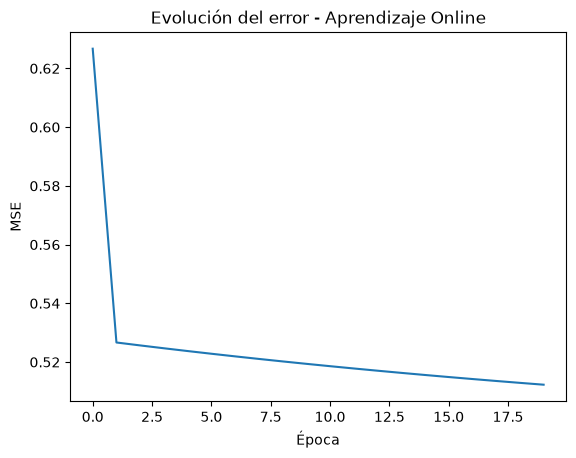

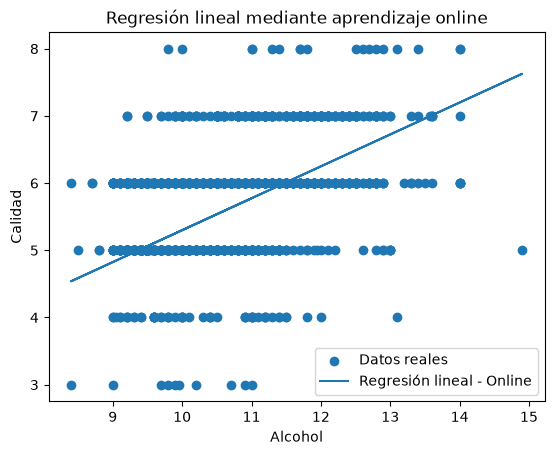

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# =========================================================
# 1. CARGAR DATOS
# =========================================================

df = pd.read_csv("winequality-red.csv", sep=";")

print(df.head())
print("\nTamaño:", df.shape)


# =========================================================
# 2. DEFINIR X E Y
# =========================================================

# X = alcohol
# y = calidad

X = df["alcohol"].values
y = df["quality"].values


# =========================================================
# 3. INICIALIZAR PARAMETROS
# =========================================================

m = 0.0
b = 0.0

# Learning rate
alpha = 0.001

# Numero de veces que recorreremos todos los datos
epochs = 20


# =========================================================
# 4. GUARDAR EL MSE DE CADA EPOCA
# =========================================================

historial_mse = []


# =========================================================
# 5. APRENDIZAJE ONLINE
# =========================================================

for epoch in range(epochs):

    errores_cuadrados = []

    # Procesamos UN DATO A LA VEZ
    for i in range(len(X)):

        # ---------------------------------------------
        # Obtener un solo dato
        # ---------------------------------------------

        x = X[i]
        real = y[i]


        # ---------------------------------------------
        # FORWARD / PREDICCION
        # ---------------------------------------------

        pred = m * x + b


        # ---------------------------------------------
        # ERROR
        # ---------------------------------------------

        error = real - pred


        # ---------------------------------------------
        # GRADIENTES
        # ---------------------------------------------

        # dE/dm = -error * x
        dm = -error * x

        # dE/db = -error
        db = -error


        # ---------------------------------------------
        # ACTUALIZAR PARAMETROS
        # ---------------------------------------------

        m = m - alpha * dm
        b = b - alpha * db


        # ---------------------------------------------
        # GUARDAR ERROR CUADRADO
        # ---------------------------------------------

        errores_cuadrados.append(error ** 2)


    # =================================================
    # MSE DE ESTA EPOCA
    # =================================================

    mse = np.mean(errores_cuadrados)

    historial_mse.append(mse)

    print(
        f"Época {epoch + 1}: "
        f"MSE = {mse:.4f}, "
        f"m = {m:.4f}, "
        f"b = {b:.4f}"
    )


# =========================================================
# 6. MOSTRAR MODELO FINAL
# =========================================================

print("\n================================")
print("MODELO FINAL")
print("================================")

print("Pendiente m:", m)
print("Intersección b:", b)

print(f"\nEcuación:")
print(f"y = {m:.4f}x + {b:.4f}")


# =========================================================
# 7. PREDICCIONES FINALES
# =========================================================

y_pred = m * X + b

print("\nPrimeras predicciones:")
print(y_pred[:10])


# =========================================================
# 8. MSE FINAL
# =========================================================

errores = y - y_pred
errores_cuadrados = errores ** 2

mse_final = np.mean(errores_cuadrados)

print("\nMSE final:", mse_final)


# =========================================================
# 9. GRAFICA DE LA EVOLUCION DEL ERROR
# =========================================================

plt.plot(historial_mse)

plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Evolución del error - Aprendizaje Online")

plt.show()


# =========================================================
# 10. GRAFICA DE LOS DATOS Y LA RECTA
# =========================================================

plt.scatter(X, y, label="Datos reales")

plt.plot(
    X,
    y_pred,
    label="Regresión lineal - Online"
)

plt.xlabel("Alcohol")
plt.ylabel("Calidad")
plt.title("Regresión lineal mediante aprendizaje online")

plt.legend()

plt.show()